#### Brian Ooi, Robin Levasseur, Keira Chang | Mathematics of Modern ML (F. Blibeche) | Mines Paris - PSL × Albert School

# Why are projects always late?
---
A project plan adds up task estimates along the longest chain of dependent tasks. Even when every
estimate is right on average, the resulting date is optimistic: the delivery date is a **maximum**
over many chains, and the average of a maximum is larger than the maximum of the averages. On top of
that, real estimates are wrong in a very asymmetric way.

The practical way to get a realistic date is to simulate the project many times, so the question
we study is:

> **Can we trust a Monte Carlo estimate of a project's delivery date, and when does it break down?**

| Part | Content |
|---|---|
| 1 | Motivation: a late dinner, and 12,299 real tasks |
| 2 | Mathematical foundations: Jensen, Clark, the Monte Carlo estimator, error bars, variance reduction |
| 3 | Implementation: the simulator in code, checked against exact results |
| 4 | Results: PERT vs Monte Carlo, which tasks matter, 480 real-size networks |
| 5 | Limitations: heavy tails, rare events, model risk. Conclusion |

The notebook runs on its own from top to bottom (*Restart & Run All*, about 20 seconds). The first time,
it downloads its two datasets (a few MB) into a folder `data/` next to it. Each function is defined in the
section that first needs it.

In [1]:
# Setup: libraries, random seed and plotting style
from dataclasses import dataclass
from pathlib import Path
import shutil
import subprocess
import time
import urllib.request
import zipfile

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

SEED = 2026  # every number in this notebook is reproducible

# Colours of the figures (series in this order), then text and reference lines.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (7, 3.6), "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

---
## 1. Motivation

### 1.1 A dinner that is late on average

Two dishes are cooked in parallel, each planned for 60 minutes. Each one takes 50 or 70 minutes
with probability 1/2, independently: **each estimate is exactly right on average**.
Dinner is ready when both dishes are, at $T = \max(D_1, D_2)$.

The four equally likely scenarios give $T = 50, 70, 70, 70$, hence
$$
\mathbb E[T] = 65 \text{ min}, \qquad P(T \le 60) = \tfrac14 .
$$

In [2]:
# Dinner example: exact answer, then Monte Carlo

# 1. Exact answer: list the 4 equally likely scenarios.
scenarios = [(d1, d2) for d1 in (50, 70) for d2 in (50, 70)]
T_exact = np.array([max(s) for s in scenarios])

# 2. Monte Carlo: simulate 100,000 dinners (one row per dinner, one column per dish).
n = 100_000
rng = np.random.default_rng(SEED)
D = np.where(rng.random((n, 2)) < 0.5, 50, 70)   # each dish: 50 or 70 minutes, probability 1/2
T = D.max(axis=1)                                # dinner is ready when both dishes are

# 3. Compare.
display(pd.DataFrame({
    "exact": [T_exact.mean(), (T_exact <= 60).mean()],
    "Monte Carlo": [T.mean(), (T <= 60).mean()],
}, index=["E[T] (minutes)", "P(dinner on time)"]).style.format(precision=4))

,exact,Monte Carlo
E[T] (minutes),65.0000,64.9368
P(dinner on time),0.2500,0.2532


**Unbiased estimates, late dinner.** Each dish is on time on average, yet dinner is 5 minutes late on
average and on time only one evening in four. With 100,000 simulated dinners, Monte Carlo finds
64.94 minutes and 25.3%, close to the exact values; Part 2 says how close we can expect it to be.

### 1.2 Real estimates are wrong, and asymmetrically so

The SiP dataset (Jones & Cullum, 2019) records the estimated and the actual effort of 12,299 tasks
from ten years of commercial software development. For each task we look at the ratio
$R = \text{actual} / \text{estimate}$: $R > 1$ means the task was late.

In [3]:
# Downloading the data (only the first time) and loading SiP
DATA_DIR = Path("data")  # a folder next to the notebook
SIP_URL = "https://raw.githubusercontent.com/Derek-Jones/SiP_dataset/master/Sip-task-info.csv"


def fetch(url, dest):
    """Download url to the file dest, unless it is already there."""
    if dest.exists():
        return
    dest.parent.mkdir(parents=True, exist_ok=True)
    print(f"downloading {url}")
    tmp = dest.with_suffix(dest.suffix + ".part")
    if shutil.which("curl"):
        # curl uses the system certificates (Python from python.org on macOS often has none).
        subprocess.run(["curl", "-fsSL", "-A", "student-project", "-o", str(tmp), url], check=True)
    else:
        request = urllib.request.Request(url, headers={"User-Agent": "student-project"})
        with urllib.request.urlopen(request) as response, open(tmp, "wb") as f:
            shutil.copyfileobj(response, f)
    tmp.rename(dest)


def load_sip():
    """SiP tasks with a positive estimate and actual effort, plus ratio = actual / estimate."""
    path = DATA_DIR / "sip" / "Sip-task-info.csv"
    fetch(SIP_URL, path)
    df = pd.read_csv(path, encoding="latin-1")  # the file is not UTF-8
    df = df[(df["HoursEstimate"] > 0) & (df["HoursActual"] > 0)].copy()
    df["ratio"] = df["HoursActual"] / df["HoursEstimate"]
    return df

In [4]:
# SiP dataset: ratio actual / estimate of each task
sip = load_sip()
ratios = sip["ratio"].to_numpy()

summary = pd.DataFrame([{
    "tasks": len(ratios),
    "median": np.median(ratios),
    "mean": ratios.mean(),
    "90th pct": np.quantile(ratios, 0.90),
    "99th pct": np.quantile(ratios, 0.99),
    "max": ratios.max(),
    "late (R > 1)": (ratios > 1).mean(),
    "R > 2": (ratios > 2).mean(),
}], index=["ratio actual / estimate"])
display(summary.style.format("{:.2f}").format("{:,.0f}", subset=["tasks"])
        .format("{:.0%}", subset=["late (R > 1)", "R > 2"]))

,tasks,median,mean,90th pct,99th pct,max,late (R > 1),R > 2
ratio actual / estimate,"12,299",1.00,1.80,3.25,8.79,281.35,38%,17%


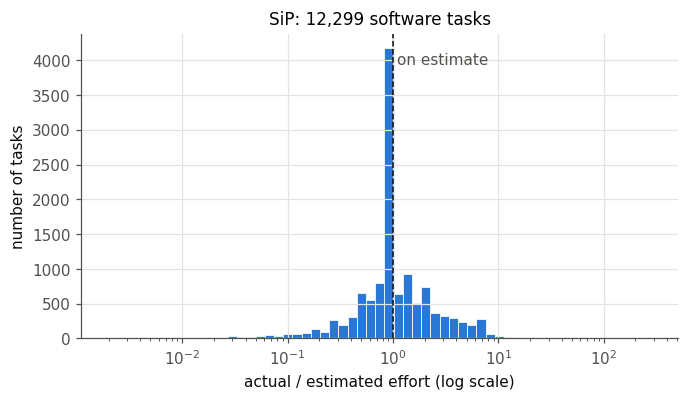

In [5]:
# Distribution of the ratios (log scale: a ratio of 10 is as far from 1 as a ratio of 0.1)
fig, ax = plt.subplots()
bins = np.logspace(np.log10(ratios.min()), np.log10(ratios.max()), 60)
ax.hist(ratios, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.axvline(1, color=INK, lw=1, ls="--")
ax.text(1.1, ax.get_ylim()[1] * 0.9, "on estimate", color=MUTED)
ax.set(xlabel="actual / estimated effort (log scale)", ylabel="number of tasks",
       title="SiP: 12,299 software tasks")
plt.show()

**A typical estimate is right; the average one is not.** Half of the tasks take no longer than
estimated (median ratio 1), but the mean ratio is 1.8, because a few tasks take 10 to 280 times their
estimate. Two effects therefore push projects late:

1. **the structure of the plan** (1.1): parallel paths make the maximum larger than the plan, even with
   unbiased estimates. This is Parts 2 to 4;
2. **the heavy tail of real overruns**: rare, huge delays. They also make Monte Carlo itself harder,
   which is Part 5.

---
## 2. Mathematical foundations

### 2.1 A project is a longest path

A project is a directed acyclic graph of $k$ tasks with random durations $D_1, \dots, D_k \ge 0$.
A task starts when all its predecessors are finished, so its finish time is
$$
F_j = D_j + \max_{i \in \mathrm{pred}(j)} F_i \qquad (F_j = D_j \text{ if } j \text{ has no predecessor}).
$$
Unrolling the recursion, the project duration is the length of the longest path:
$$
T = g(D) := \max_{P \in \mathcal P} L_P(D), \qquad L_P(D) = \sum_{i \in P} D_i ,
$$
where $\mathcal P$ is the set of paths from a first task to a last task. The classical PERT method
replaces each duration by its mean: $T_{\mathrm{PERT}} = g(\mathbb E[D])$.

### 2.2 The plan is optimistic

**Proposition 1.** $\mathbb E[T] \ge T_{\mathrm{PERT}}$, whatever the law of the durations.

*Proof.* For every path $P$, $T \ge L_P(D)$, so $\mathbb E[T] \ge \mathbb E[L_P(D)] = L_P(\mathbb E[D])$
by linearity. Taking the maximum over $P$ gives $\mathbb E[T] \ge \max_P L_P(\mathbb E[D]) = T_{\mathrm{PERT}}$. $\square$

This is Jensen's inequality for the convex function $g$ (a maximum of linear functions). The gap is
zero only if one path is almost surely the longest: **the delay comes from paths competing**.

### Remark (tropical view)

In the **max-plus algebra**, $a \oplus b = \max(a, b)$ (tasks in parallel: wait for the later one) and $a \otimes b = a + b$ (tasks in series), with tropical zero $-\infty$ and unit $0$. As in ordinary algebra, $\otimes$ distributes over $\oplus$: $a + \max(b, c) = \max(a + b, a + c)$.

Expanding the recursion of Section 2.1 with this rule gives $\displaystyle T = \bigoplus_{P \in \mathcal P} \bigotimes_{i \in P} D_i = \max_{P \in \mathcal P} \sum_{i \in P} D_i$:
$T$ is a **tropical polynomial** in the durations, i.e. a maximum of linear functions, hence convex. This is a one-line proof of the convexity used by Jensen in Proposition 1.

Expectation passes through $\otimes$, since $\mathbb E[a + b] = \mathbb E[a] + \mathbb E[b]$, but not through $\oplus$, since $\mathbb E[\max(a, b)] \ge \max(\mathbb E[a], \mathbb E[b])$.
PERT computes tropically with the means, as if $\mathbb E$ passed through $\oplus$: this is exactly why the plan is optimistic (dinner: plan 60 min, $\mathbb E[T] = 65$ min).

**Limitation.** Tropical algebra describes $T$ for *fixed* durations; it does not give the law of $T$ when the durations are random, which is #P-hard (Section 2.4), so we still need Monte Carlo: the two approaches are complementary.

### 2.3 Two parallel paths in closed form

**Proposition 2 (Clark, 1961).** Let $(X_1, X_2)$ be Gaussian with means $\mu_1, \mu_2$, standard
deviations $\sigma_1, \sigma_2$ and correlation $\rho$. Let
$\theta = \sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2} > 0$ and $\alpha = (\mu_1 - \mu_2)/\theta$. Then
$$
\mathbb E[\max(X_1, X_2)] = \mu_1 \Phi(\alpha) + \mu_2 \Phi(-\alpha) + \theta\, \varphi(\alpha).
$$

*Proof.* $\max(X_1, X_2) = X_2 + (X_1 - X_2)^+$ and $Y = X_1 - X_2 \sim \mathcal N(\mu_1 - \mu_2, \theta^2)$.
Write $Y = a + \theta Z$ with $a = \mu_1 - \mu_2$ and $Z \sim \mathcal N(0, 1)$. Since
$\mathbb E[Z \mathbf 1\{Z > c\}] = \varphi(c)$,
$$
\mathbb E[Y^+] = \mathbb E[(a + \theta Z)\mathbf 1\{Z > -\alpha\}] = a\,\Phi(\alpha) + \theta\,\varphi(\alpha).
$$
Hence $\mathbb E[\max] = \mu_2 + (\mu_1 - \mu_2)\Phi(\alpha) + \theta\varphi(\alpha)$, which is the formula because $1 - \Phi(\alpha) = \Phi(-\alpha)$. $\square$

**Corollary.** If $\mu_1 = \mu_2 = \mu$, then $\mathbb E[\max] = \mu + \theta / \sqrt{2\pi}$: two paths that are
on time on average give a project that is late on average, by an amount proportional to the uncertainty $\theta$.

### 2.4 In general there is no formula

For a real network, computing $P(T \le t)$, or even $\mathbb E[T]$, is **#P-hard**, already when each
duration takes only two values (Hagstrom, 1988): it is at least as hard as counting the solutions of an NP-complete
problem, so no efficient exact algorithm is expected. The number of paths can grow exponentially with $k$,
and paths sharing tasks are correlated. Analytic shortcuts such as applying Clark's formula at every
merge (Sculli, 1983) must ignore these correlations; Section 3.6 measures the error this causes.
We therefore **simulate**.

### 2.5 The Monte Carlo estimator

Draw i.i.d. scenarios $D^{(1)}, \dots, D^{(n)}$ and compute $T^{(s)} = g(D^{(s)})$. We estimate

| quantity | estimator |
|---|---|
| expected duration $\mu = \mathbb E[T]$ | $\hat\mu_n = \frac1n \sum_s T^{(s)}$ |
| probability of being on time $p = P(T \le t)$ | $\hat p_n = \frac1n \sum_s \mathbf 1\{T^{(s)} \le t\}$ |
| date met with probability $q$ (e.g. the 90% date) $\xi_q$ | empirical $q$-quantile of the $T^{(s)}$ |

**Proposition 3.** $\hat\mu_n$ is unbiased and $\hat\mu_n \to \mu$ almost surely (law of large numbers).
If $\sigma^2 = \mathrm{Var}(T) < \infty$, then $\sqrt n\,(\hat\mu_n - \mu) \to \mathcal N(0, \sigma^2)$ (CLT), which gives
the asymptotic 95% interval $\hat\mu_n \pm 1.96\, \hat\sigma_n / \sqrt n$.

The error depends on $n$ and $\sigma$ only, **not on the number of tasks $k$**: only the cost of one
simulation grows, linearly in $k$ plus the number of precedence arcs. A grid over the $k$ durations
would need $N^k$ points instead.

### 2.6 Error bars with guarantees

**Proposition 4 (Hoeffding interval for the probability of being on time).** For every $n$ and $\delta \in (0, 1)$,
$$
P\big(|\hat p_n - p| \ge \varepsilon_n\big) \le \delta, \qquad \varepsilon_n = \sqrt{\frac{\ln(2/\delta)}{2n}} .
$$

*Proof.* The indicators $\mathbf 1\{T^{(s)} \le t\}$ are i.i.d. with values in $[0, 1]$ and mean $p$.
Hoeffding's inequality gives $P(|\hat p_n - p| \ge \varepsilon) \le 2e^{-2n\varepsilon^2}$. Setting the right-hand side equal to $\delta$ gives $\varepsilon_n$. $\square$

This interval holds for every $n$ (not only asymptotically) and for every law of the durations,
heavy tails included. For example, $\pm 1\%$ at 95% requires $n \ge \ln(40) / (2 \cdot 10^{-4}) \approx 18{,}445$ simulations.

**Proposition 5 (interval for a quantile).** Assume $T$ has a continuous distribution, and let
$T_{(1)} \le \dots \le T_{(n)}$ be the sorted sample and $N = \#\{s : T^{(s)} \le \xi_q\} \sim \mathrm{Bin}(n, q)$.
For ranks $l < u$,
$$
P\big(T_{(l)} \le \xi_q < T_{(u)}\big) = P(l \le N \le u - 1).
$$

*Proof.* $T_{(l)} \le \xi_q$ if and only if at least $l$ samples are $\le \xi_q$, i.e. $N \ge l$, and
$\xi_q < T_{(u)}$ if and only if $N \le u - 1$. $\square$

Choosing $l$ and $u$ from binomial quantiles makes this probability at least $1 - \delta$. Again **no
moment assumption** is needed. Finally, the Dvoretzky-Kiefer-Wolfowitz inequality (with Massart's
constant) gives a band around the whole CDF: $P\big(\sup_t |\hat F_n(t) - F(t)| > \varepsilon\big) \le 2 e^{-2n\varepsilon^2}$,
the same radius as Hoeffding, but valid for all deadlines $t$ at once.

### 2.7 Variance reduction

Every duration model in our code (Section 3.2) draws durations by inverse transform, $D_i = F_i^{-1}(U_i)$ with $U$ uniform on
$[0,1]^k$, so $T = h(U)$ where $h$ is nondecreasing in each coordinate ($g$ and every $F_i^{-1}$ are nondecreasing).

**Proposition 6 (antithetic variables).** $\mathrm{Cov}\big(h(U), h(\mathbf 1 - U)\big) \le 0$. Consequently
$$
\mathrm{Var}\Big(\tfrac{h(U) + h(\mathbf 1 - U)}{2}\Big) \le \tfrac12\,\mathrm{Var}(T):
$$
one antithetic pair is at least as precise as two independent simulations.

*Proof for $k = 1$.* Let $a(u) = h(u)$, nondecreasing, and $b(u) = h(1 - u)$, nonincreasing. For $U, V$
independent uniforms, $(a(U) - a(V))(b(U) - b(V)) \le 0$ since the two factors have opposite signs.
Taking expectations, $2\,\mathbb E[a(U)b(U)] - 2\,\mathbb E[a(U)]\,\mathbb E[b(U)] \le 0$, i.e.
$\mathrm{Cov}(a(U), b(U)) \le 0$. For $k > 1$ the same holds by induction over the coordinates
(Harris inequality; Esary, Proschan & Walkup, 1967). Finally
$\mathrm{Var}\big(\tfrac{A + B}{2}\big) = \tfrac14(\mathrm{Var} A + \mathrm{Var} B + 2\,\mathrm{Cov}(A, B)) \le \tfrac12 \mathrm{Var}(T)$. $\square$

**Proposition 7 (control variate).** Let $C$ be a variable with known mean. For every $\beta$,
$\hat\mu_\beta = \overline T - \beta(\overline C - \mathbb E[C])$ is unbiased, and its variance is minimal for
$\beta^* = \mathrm{Cov}(T, C) / \mathrm{Var}(C)$, where it equals $(1 - \rho^2)\,\mathrm{Var}(T)/n$ with $\rho = \mathrm{corr}(T, C)$.

*Proof.* $\mathrm{Var}(T - \beta C) = \mathrm{Var}\,T - 2\beta\,\mathrm{Cov}(T, C) + \beta^2\, \mathrm{Var}\,C$ is a
quadratic in $\beta$, minimal at $\beta^*$, with minimum $\mathrm{Var}\,T - \mathrm{Cov}(T, C)^2/\mathrm{Var}\,C = (1 - \rho^2)\,\mathrm{Var}\,T$. $\square$

We take $C$ = length of the PERT critical path $P^*$: $\mathbb E[C] = \sum_{i \in P^*} \mathbb E[D_i]$ is known
exactly, and $C$ is strongly correlated with $T$ because $P^*$ is often the longest path.

Parts 4 and 5 add two results: the criticality index of a task is a derivative of $\mathbb E[T]$ (Part 4), and
heavy tails break the CLT but not Propositions 4 and 5 (Part 5).

---
## 3. Implementation and validation

This part turns Part 2 into code, then checks the code against exact results before Parts 4 and 5 rely on it.
The simulator has three pieces: the project network and its longest path (3.1), the laws of the task
durations (3.2), and the Monte Carlo estimators with their error bars (3.4).

### 3.1 The project network

A project is stored as the list of predecessors of each task. The tasks are first put in **topological
order**, an order in which every task comes after its predecessors (Kahn's algorithm: repeatedly take a task
whose predecessors are all placed). The forward pass then applies $F_j = D_j + \max_{i \in \mathrm{pred}(j)} F_i$
in that order (Section 2.1).

To simulate fast, $n$ scenarios are stored in a matrix $D$ of shape $(n, k)$: one row per scenario, one column
per task. The loop runs over the $k$ tasks only, and each step updates a whole column, i.e. all $n$ scenarios at
once with NumPy. The cost is proportional to $n$ times the number of tasks and arcs. The longest path of each
scenario (used in Part 4) is found by walking back from the last task to finish, each time to the predecessor
that finished last.

In [6]:
class Project:
    """A project network: k tasks, their planned durations and their predecessors."""

    def __init__(self, durations, predecessors, names=None):
        self.durations = np.asarray(durations, dtype=float)       # planned duration of each task
        self.k = len(self.durations)
        self.predecessors = [[int(i) for i in p] for p in predecessors]  # tasks to finish before j starts
        self.successors = [[] for _ in range(self.k)]
        for j, preds in enumerate(self.predecessors):
            for i in preds:
                self.successors[i].append(j)
        self.names = list(names) if names is not None else [str(j) for j in range(self.k)]
        self.order = self._topological_order()
        self.terminals = np.array([j for j in range(self.k) if not self.successors[j]])  # final tasks

    @classmethod
    def from_successors(cls, durations, successors, names=None):
        """Build a project from successor lists (the format of PSPLIB, Section 4.3)."""
        preds = [[] for _ in successors]
        for i, succ in enumerate(successors):
            for j in succ:
                preds[j].append(i)
        return cls(durations, preds, names)

    def _topological_order(self):
        """Kahn's algorithm: repeatedly take a task whose predecessors are all placed."""
        missing = [len(p) for p in self.predecessors]  # predecessors not placed yet
        ready = [j for j in range(self.k) if missing[j] == 0]
        order = []
        while ready:
            i = ready.pop()
            order.append(i)
            for j in self.successors[i]:
                missing[j] -= 1
                if missing[j] == 0:
                    ready.append(j)
        if len(order) != self.k:
            raise ValueError("the precedence graph has a cycle")
        return order

    def _forward_pass(self, D):
        """Finish times F (n, k) of all scenarios, and for each task the predecessor that finished last."""
        D = np.atleast_2d(np.asarray(D, dtype=float))  # one row per scenario
        rows = np.arange(D.shape[0])
        F = np.empty_like(D)
        last_pred = np.full(D.shape, -1)               # -1 = no predecessor
        for j in self.order:                           # k steps, each on all n scenarios at once
            preds = self.predecessors[j]
            if preds:
                Fp = F[:, preds]
                best = Fp.argmax(axis=1)               # the predecessor that finishes last
                F[:, j] = Fp[rows, best] + D[:, j]
                last_pred[:, j] = np.asarray(preds)[best]
            else:
                F[:, j] = D[:, j]
        return F, last_pred

    def completion_time(self, D):
        """Project duration T = longest path, one value per scenario."""
        F, _ = self._forward_pass(D)
        return F[:, self.terminals].max(axis=1)

    def planned_duration(self):
        """Longest path when every task takes its planned duration: the naive plan."""
        return float(self.completion_time(self.durations)[0])

    def critical_tasks(self, D):
        """Boolean array (n, k): is task j on the longest path of scenario s?

        Walk back from the final task that finishes last, each time to the predecessor that
        finished last. Ties go to the first predecessor (they have probability 0 for continuous laws).
        """
        F, last_pred = self._forward_pass(D)
        n = F.shape[0]
        rows = np.arange(n)
        on_path = np.zeros(F.shape, dtype=bool)
        task = self.terminals[F[:, self.terminals].argmax(axis=1)]  # last task to finish
        walking = np.ones(n, dtype=bool)                            # scenarios not back at the start yet
        while walking.any():
            on_path[rows[walking], task[walking]] = True
            previous = last_pred[rows, task]
            walking &= previous >= 0
            task = np.where(walking, previous, 0)
        return on_path

    def critical_path(self, D=None):
        """Tasks on the longest path of one scenario (the planned durations by default)."""
        D = self.durations if D is None else D
        on_path = self.critical_tasks(D)[0]
        return [j for j in self.order if on_path[j]]

### 3.2 Task durations

Every law is coded through its inverse CDF, `ppf` (SciPy's name): uniforms $U$ of shape $(n, k)$ become
durations $D_i = F_i^{-1}(U_i)$, one column per task, so the tasks are independent. This inverse transform is
what makes antithetic variables (Proposition 6) a one-line change: use $U$ and $\mathbf 1 - U$. We need three laws:

* `Normal`: Gaussian durations. They can be negative, so we use them only to compare with Clark's formula.
* `BetaPERT`: the classical three-point model (Malcolm et al., 1959). From an optimistic $a$, a most likely $m$
  and a pessimistic $b$: $D = a + (b - a)X$ with $X \sim \mathrm{Beta}(\alpha, \beta)$,
  $\alpha = 1 + 4\frac{m - a}{b - a}$ and $\beta = 1 + 4\frac{b - m}{b - a}$, so that $\mathbb E[D] = (a + 4m + b)/6$.
* `EmpiricalRatio`: real delays. Each task takes its planned duration times a ratio actual / estimate drawn at
  random among the 12,299 SiP tasks of Section 1.2 (a bootstrap).

In [7]:
class DurationModel:
    """A law of the k task durations, given by its inverse CDF (column i drives task i)."""

    def ppf(self, U):
        """Map uniforms U of shape (n, k) to durations of shape (n, k)."""
        raise NotImplementedError

    def mean(self):
        """Exact expected duration of each task, shape (k,)."""
        raise NotImplementedError

    def var(self):
        """Exact variance of each task's duration, shape (k,)."""
        raise NotImplementedError

    def sample(self, n, rng=None):
        """n independent scenarios, shape (n, k)."""
        rng = np.random.default_rng(rng)
        return self.ppf(rng.random((n, self.k)))


class Normal(DurationModel):
    """D_i ~ N(mu_i, sigma_i^2). Can be negative: only used to check Clark's formula."""

    def __init__(self, mu, sigma):
        self.mu, self.sigma = np.asarray(mu, dtype=float), np.asarray(sigma, dtype=float)
        self.k = len(self.mu)

    def ppf(self, U):
        return self.mu + self.sigma * stats.norm.ppf(U)

    def mean(self):
        return self.mu.copy()

    def var(self):
        return self.sigma**2


class BetaPERT(DurationModel):
    """D = a + (b - a) X with X ~ Beta(alpha, beta): mean (a + 4m + b) / 6."""

    def __init__(self, a, m, b):
        self.a, self.m, self.b = (np.asarray(x, dtype=float) for x in (a, m, b))
        self.k = len(self.a)
        width = np.where(self.b > self.a, self.b - self.a, 1.0)  # a == b: a fixed duration
        self.alpha = 1 + 4 * (self.m - self.a) / width
        self.beta = 1 + 4 * (self.b - self.m) / width

    def ppf(self, U):
        return self.a + (self.b - self.a) * stats.beta.ppf(U, self.alpha, self.beta)

    def sample(self, n, rng=None):
        # Same law as ppf(uniforms), but about 20 times faster than inverting the Beta CDF.
        rng = np.random.default_rng(rng)
        return self.a + (self.b - self.a) * rng.beta(self.alpha, self.beta, size=(n, self.k))

    def mean(self):
        return (self.a + 4 * self.m + self.b) / 6

    def var(self):
        s = self.alpha + self.beta
        return (self.b - self.a) ** 2 * self.alpha * self.beta / (s**2 * (s + 1))


class EmpiricalRatio(DurationModel):
    """D_i = planned_i x R_i, with R_i drawn at random among observed ratios (a bootstrap).

    The inverse CDF of R is the empirical quantile function of the observed ratios.
    """

    def __init__(self, planned, ratios):
        self.planned = np.asarray(planned, dtype=float)
        self.ratios = np.sort(np.asarray(ratios, dtype=float))
        self.k = len(self.planned)

    def ppf(self, U):
        m = len(self.ratios)
        return self.planned * self.ratios[np.minimum((U * m).astype(int), m - 1)]

    def mean(self):
        return self.planned * self.ratios.mean()

    def var(self):
        return self.planned**2 * self.ratios.var()

### 3.3 The running example

A 7-task software project. Each task has a three-point estimate (optimistic $a$, most likely $m$,
pessimistic $b$) and follows the Beta-PERT law of Section 3.2.

```
spec ──┬── backend ──┐
       ├── frontend ─┼── integration ──┐
       ├── database ─┘                 ├── release
       └── docs ───────────────────────┘
```

In [8]:
# The running example: a 7-task software project, durations in days
names = ["spec", "backend", "frontend", "database", "docs", "integration", "release"]
optimistic = [3, 7, 6, 4, 2, 3, 1]
most_likely = [5, 10, 9, 6, 4, 5, 1]      # the plan
pessimistic = [9, 20, 18, 12, 8, 12, 2]
after = [[], [0], [0], [0], [0], [1, 2, 3], [4, 5]]  # predecessors of each task

project = Project(most_likely, after, names)
pert_model = BetaPERT(optimistic, most_likely, pessimistic)


def pert_duration(project, model):
    """The classical PERT date: the longest path with mean durations (Section 2.1)."""
    return float(project.completion_time(model.mean())[0])


tasks = pd.DataFrame({
    "a": pert_model.a, "m": pert_model.m, "b": pert_model.b,
    "mean": pert_model.mean(), "std": np.sqrt(pert_model.var()),
    "after": [", ".join(project.names[i] for i in p) or "-" for p in project.predecessors],
}, index=project.names)
display(tasks.style.format(precision=2))

print("plan with most likely durations :", project.planned_duration(), "days")
print("PERT date (mean durations)      :", pert_duration(project, pert_model), "days")
print("PERT critical path              :", [project.names[i] for i in project.critical_path(pert_model.mean())])

,a,m,b,mean,std,after
spec,3.00,5.00,9.00,5.33,1.11,-
backend,7.00,10.00,20.00,11.17,2.29,spec
frontend,6.00,9.00,18.00,10.00,2.14,spec
database,4.00,6.00,12.00,6.67,1.43,spec
docs,2.00,4.00,8.00,4.33,1.11,spec
integration,3.00,5.00,12.00,5.83,1.58,"backend, frontend, database"
release,1.00,1.00,2.00,1.17,0.14,"docs, integration"


plan with most likely durations : 21.0 days
PERT date (mean durations)      : 23.5 days
PERT critical path              : ['spec', 'backend', 'integration', 'release']


**The forward pass, step by step.** `Project.completion_time` visits the tasks once in topological order (every task after its
predecessors) and applies $F_j = D_j + \max_{i \in \mathrm{pred}(j)} F_i$. Below, the same computation for a single
scenario, written as a plain loop.

In [9]:
# Longest path of ONE scenario, by hand

# 1. Draw one scenario of the 7 durations.
d = pert_model.sample(1, rng=SEED)[0]

# 2. A task starts when its last predecessor ends.
finish = {}
for j in project.order:
    start = max((finish[i] for i in project.predecessors[j]), default=0.0)
    finish[j] = start + d[j]
    print(f"{project.names[j]:12s} starts {start:6.2f}   lasts {d[j]:5.2f}   ends {finish[j]:6.2f}")

# 3. The project ends with its last task. Compare with the vectorised code.
print(f"\nT by hand: {max(finish.values()):.4f}    T from Project.completion_time: {project.completion_time(d)[0]:.4f}")

spec         starts   0.00   lasts  6.21   ends   6.21
docs         starts   6.21   lasts  3.94   ends  10.15
database     starts   6.21   lasts  6.28   ends  12.49
frontend     starts   6.21   lasts  8.46   ends  14.67
backend      starts   6.21   lasts 12.78   ends  18.99
integration  starts  18.99   lasts  5.12   ends  24.12
release      starts  24.12   lasts  1.12   ends  25.23

T by hand: 25.2327    T from Project.completion_time: 25.2327


In [10]:
# Project.completion_time does the same loop, but each step handles all n scenarios at once (a NumPy column).
start = time.perf_counter()
T = project.completion_time(pert_model.sample(100_000, rng=SEED))
print(f"100,000 simulations in {time.perf_counter() - start:.2f} s, E[T] ~ {T.mean():.2f} days")

100,000 simulations in 0.02 s, E[T] ~ 24.26 days


### 3.4 The Monte Carlo estimator and its error bars

`simulate` draws $n$ scenarios and returns the $n$ project durations $T^{(s)}$. With `antithetic=True` it draws
$n/2$ uniform vectors $U$ and returns the $n/2$ averages $\big(T(U) + T(\mathbf 1 - U)\big)/2$ (Proposition 6). These
averages are i.i.d., so the same intervals apply to them, for the same number $n$ of longest-path computations.

Each interval function returns an `Estimate` (value, lower and upper bound) and implements one result of Part 2:

| function | 95% interval for | result | assumption |
|---|---|---|---|
| `mean_ci` | $\mathbb E[T]$ | CLT (Proposition 3) | $\mathrm{Var}(T) < \infty$, $n$ large |
| `prob_ci` | $P(T \le t)$ | Hoeffding (Proposition 4), or CLT | none (Hoeffding) |
| `quantile_ci` | the $q$-quantile, e.g. the 90% date | order statistics (Proposition 5) | $T$ continuous |
| `dkw_radius` | the whole CDF of $T$ | DKW inequality | none |

In [11]:
@dataclass
class Estimate:
    """A point estimate with its confidence interval [low, high]."""

    value: float
    low: float
    high: float
    n: int
    method: str

    @property
    def radius(self):
        return (self.high - self.low) / 2

    @property
    def interval(self):
        """The interval as text, for tables."""
        return f"[{self.low:.4g}, {self.high:.4g}]"

    def __contains__(self, x):  # lets us write `true_value in estimate`
        return self.low <= x <= self.high


def simulate(project, model, n, rng=None, antithetic=False, return_durations=False):
    """n simulated project durations (or n // 2 antithetic pair averages, see above)."""
    rng = np.random.default_rng(rng)
    if antithetic:
        U = rng.random((n // 2, project.k))
        return (project.completion_time(model.ppf(U)) + project.completion_time(model.ppf(1 - U))) / 2
    D = model.sample(n, rng)
    T = project.completion_time(D)
    return (T, D) if return_durations else T


def mean_ci(x, level=0.95):
    """CLT interval for E[X]: mean +/- z s / sqrt(n) (Proposition 3)."""
    x = np.asarray(x, dtype=float)
    m = x.mean()
    r = stats.norm.ppf(0.5 + level / 2) * x.std(ddof=1) / np.sqrt(len(x))
    return Estimate(m, m - r, m + r, len(x), "CLT")


def prob_ci(event, level=0.95, method="hoeffding"):
    """Interval for p = P(event) from 0/1 outcomes.

    hoeffding: p_hat +/- sqrt(log(2/delta) / (2n)), valid for every n (Proposition 4).
    clt:       p_hat +/- z sqrt(p_hat (1 - p_hat) / n), narrower but only asymptotic.
    """
    e = np.asarray(event, dtype=float)
    n, p = len(e), e.mean()
    if method == "hoeffding":
        r = np.sqrt(np.log(2 / (1 - level)) / (2 * n))
    else:
        r = stats.norm.ppf(0.5 + level / 2) * np.sqrt(p * (1 - p) / n)
    return Estimate(p, max(0.0, p - r), min(1.0, p + r), n, method)


def quantile_ci(x, q, level=0.95):
    """Interval for the q-quantile between two order statistics (Proposition 5).

    The number of samples below the true quantile is Binomial(n, q): its quantiles give the ranks.
    """
    xs = np.sort(np.asarray(x, dtype=float))
    n, delta = len(xs), 1 - level
    lo = max(int(stats.binom.ppf(delta / 2, n, q)), 1)  # ranks, counted from 1
    hi = min(int(stats.binom.ppf(1 - delta / 2, n, q)) + 1, n)
    value = float(np.quantile(xs, q, method="inverted_cdf"))
    return Estimate(value, float(xs[lo - 1]), float(xs[hi - 1]), n, "order statistics")


def dkw_radius(n, level=0.95):
    """DKW band: sup_t |F_n(t) - F(t)| <= sqrt(log(2/delta) / (2n)), for all t at once."""
    return float(np.sqrt(np.log(2 / (1 - level)) / (2 * n)))

### 3.5 Validation against an exact formula

Two parallel tasks with Gaussian durations: $\mathbb E[T]$ is given by Clark's formula (Proposition 2).
One interval missing the truth proves little (a 95% interval misses 5% of the time), so we repeat the
experiment and look at the standardised errors $z = (\hat\mu_n - \mu) / (\hat\sigma_n / \sqrt n)$,
which should behave like $\mathcal N(0, 1)$.

In [12]:
def clark_max(mu1, s1, mu2, s2, rho=0.0):
    """Exact mean and standard deviation of max(X1, X2) for jointly Gaussian X1, X2 (Clark, 1961).

    The mean is Proposition 2. The second moment, used for the standard deviation, is
    E[max^2] = (mu1^2 + s1^2) Phi(alpha) + (mu2^2 + s2^2) Phi(-alpha) + (mu1 + mu2) theta phi(alpha).
    """
    theta2 = s1**2 + s2**2 - 2 * rho * s1 * s2
    if theta2 <= 1e-300:  # X1 - X2 is constant: the max is simply the larger one
        return (mu1, s1) if mu1 >= mu2 else (mu2, s2)
    theta = np.sqrt(theta2)
    alpha = (mu1 - mu2) / theta
    P, Q, density = stats.norm.cdf(alpha), stats.norm.cdf(-alpha), stats.norm.pdf(alpha)
    m1 = mu1 * P + mu2 * Q + theta * density
    m2 = (mu1**2 + s1**2) * P + (mu2**2 + s2**2) * Q + (mu1 + mu2) * theta * density
    return float(m1), float(np.sqrt(max(m2 - m1**2, 0.0)))

In [13]:
# Parameters of the experiment
mu = np.array([10.0, 10.5])      # mean durations of the two tasks
sigma = np.array([2.0, 3.0])     # standard deviations
n, repetitions = 20_000, 200

In [14]:
# Monte Carlo versus Clark's exact formula

# 1. Exact value.
two_tasks = Project([0, 0], [[], []])          # two tasks, no precedence: T = max(D1, D2)
exact_mean, _ = clark_max(mu[0], sigma[0], mu[1], sigma[1])

# 2. Repeat the Monte Carlo estimate and standardise its error.
normal_model = Normal(mu, sigma)
z = []
for rep in range(repetitions):
    est = mean_ci(simulate(two_tasks, normal_model, n, rng=rep))
    z.append((est.value - exact_mean) / (est.radius / 1.96))
z = np.array(z)

# 3. Compare with N(0, 1).
print(f"Clark (exact)              : {exact_mean:.4f}")
print(f"mean of z  (target 0)      : {z.mean():.3f}")
print(f"std of z   (target 1)      : {z.std():.3f}")
print(f"coverage   (target 0.95)   : {(np.abs(z) < 1.96).mean():.3f}")

Clark (exact)              : 11.7022
mean of z  (target 0)      : -0.042
std of z   (target 1)      : 0.951
coverage   (target 0.95)   : 0.955


**The simulator agrees with the exact formula.** The standardised errors are centred, with unit
variance, and the intervals cover the exact value about 95% of the time.

### 3.6 An analytic shortcut is biased

For a whole network, Sculli (1983) applies Clark's formula at every merge and treats the merging paths
as independent. In our example they are not: backend, frontend and database all start when spec ends.
With Gaussian durations of the same mean and variance as the Beta-PERT ones:

In [15]:
def sculli(project, mu, sigma):
    """Sculli (1983): mean and std of T for independent N(mu_i, sigma_i^2) tasks, approximately.

    Keep a Gaussian approximation of every finish time, in topological order. At a merge, fold
    Clark's formula over the predecessors as if they were independent (rho = 0).
    """
    fin_mean, fin_sd = np.zeros(project.k), np.zeros(project.k)

    def fold_max(tasks):
        m, s = fin_mean[tasks[0]], fin_sd[tasks[0]]
        for i in tasks[1:]:
            m, s = clark_max(m, s, fin_mean[i], fin_sd[i], rho=0.0)
        return m, s

    for j in project.order:
        preds = project.predecessors[j]
        start_m, start_s = fold_max(preds) if preds else (0.0, 0.0)
        fin_mean[j] = start_m + mu[j]
        fin_sd[j] = np.sqrt(start_s**2 + sigma[j] ** 2)
    return fold_max(list(project.terminals))

In [16]:
# Sculli's approximation versus Monte Carlo (Gaussian durations)
mu, sigma = pert_model.mean(), np.sqrt(pert_model.var())
approx_mean, approx_sd = sculli(project, mu, sigma)
T = simulate(project, Normal(mu, sigma), n=200_000, rng=SEED)
est = mean_ci(T)

display(pd.DataFrame({
    "E[T]": [approx_mean, est.value], "std of T": [approx_sd, T.std()],
    "95% interval for E[T]": ["-", est.interval],
}, index=["Sculli (independence assumed)", "Monte Carlo"]).style.format(precision=3))
print(f"bias of the approximation: {approx_mean - est.value:+.3f} days, "
      f"about {(approx_mean - est.value) / (est.radius / 1.96):.0f} Monte Carlo standard errors")

,E[T],std of T,95% interval for E[T]
Sculli (independence assumed),24.418,2.595,-
Monte Carlo,24.259,2.694,"[24.25, 24.27]"


bias of the approximation: +0.159 days, about 26 Monte Carlo standard errors


**Ignoring correlations overestimates the delay.** Paths that share a task are positively
correlated, and the maximum of positively correlated variables is smaller than the maximum of
independent ones with the same laws. The bias is small here, but it is far outside the Monte Carlo
error bars, and nothing in the formula warns about it.

### 3.7 The error decreases like $1/\sqrt n$

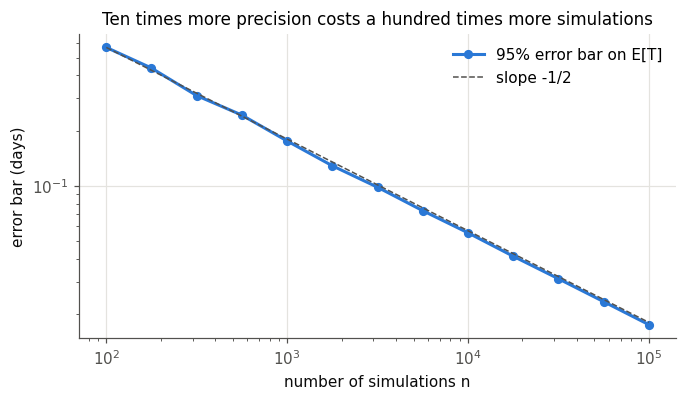

In [17]:
# Width of the 95% CLT interval for E[T] as n grows
sizes = np.logspace(2, 5, 13).astype(int)
radii = [mean_ci(simulate(project, pert_model, n, rng=SEED + i)).radius
         for i, n in enumerate(sizes)]

fig, ax = plt.subplots()
ax.loglog(sizes, radii, "o-", color=BLUE, ms=5, label="95% error bar on E[T]")
ax.loglog(sizes, radii[0] * np.sqrt(sizes[0] / sizes), "--", color=MUTED, lw=1, label="slope -1/2")
ax.set(xlabel="number of simulations n", ylabel="error bar (days)",
       title="Ten times more precision costs a hundred times more simulations")
ax.legend()
plt.show()

### 3.8 Coverage experiment

Do the 95% intervals of Section 2.6 really contain the true value 95% of the time? We repeat a small
study of $n = 500$ simulations 1,000 times. The "true" values come from one run of 2,000,000 simulations.

In [18]:
# Parameters of the experiment
n, repetitions = 500, 1_000
deadline = 25                     # days: P(T <= 25) is the probability of being on time

In [19]:
def coverage(sample_fn, ci_fn, true_value, reps=500, rng=None):
    """Fraction of `reps` independent studies whose interval contains true_value.

    sample_fn(rng) returns one Monte Carlo sample, ci_fn(sample) its Estimate.
    """
    rng = np.random.default_rng(rng)
    return sum(true_value in ci_fn(sample_fn(rng)) for _ in range(reps)) / reps

In [20]:
# Empirical coverage of four 95% intervals

# 1. Reference values from a very large run.
T_ref = simulate(project, pert_model, n=2_000_000, rng=1)
true_mean, true_p, true_q90 = T_ref.mean(), (T_ref <= deadline).mean(), np.quantile(T_ref, 0.9)

# 2. Repeat a small study and count how often each interval contains the truth.
small_study = lambda rng: simulate(project, pert_model, n, rng=rng)
coverage_table = pd.Series({
    "CLT, E[T]": coverage(small_study, mean_ci, true_mean, repetitions, rng=SEED),
    "Hoeffding, P(on time)": coverage(small_study, lambda T: prob_ci(T <= deadline),
                                         true_p, repetitions, rng=SEED),
    "CLT, P(on time)": coverage(small_study, lambda T: prob_ci(T <= deadline, method="clt"),
                                   true_p, repetitions, rng=SEED),
    "order statistics, 90% date": coverage(small_study, lambda T: quantile_ci(T, 0.9),
                                              true_q90, repetitions, rng=SEED),
}, name="coverage (target 95%)")
display(coverage_table.to_frame().style.format("{:.1%}"))

,coverage (target 95%)
"CLT, E[T]",94.5%
"Hoeffding, P(on time)",99.5%
"CLT, P(on time)",94.3%
"order statistics, 90% date",96.0%


**All four intervals keep their promise here.** Hoeffding over-covers: it holds for every $n$ and
every distribution, so it is conservative. The CLT intervals are close to 95% because Beta-PERT
durations are bounded. Part 5 repeats this experiment with heavy-tailed delays.

### 3.9 Variance reduction in practice

Antithetic pairs are an option of `simulate` (Section 3.4). For the control variate (Proposition 7), $C$ is the length of the
PERT critical path, and $\beta^*$ is estimated on the same sample.

In [21]:
def control_variate(y, c, c_mean, level=0.95):
    """Control-variate estimate of E[y] (Proposition 7), where c has the known mean c_mean.

    Estimating beta on the same sample adds a bias of order 1/n, negligible here.
    Returns (estimate, beta, corr(y, c)).
    """
    y, c = np.asarray(y, dtype=float), np.asarray(c, dtype=float)
    cov = np.cov(y, c)
    beta = cov[0, 1] / cov[1, 1]
    corr = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    est = mean_ci(y - beta * (c - c_mean), level)
    est.method = "CLT + control variate"
    return est, float(beta), float(corr)

In [22]:
# Same budget (n = 20,000 longest-path evaluations), three estimators of E[T]
n = 20_000

# 1. Plain Monte Carlo and antithetic pairs.
plain = mean_ci(simulate(project, pert_model, n, rng=SEED))
antithetic = mean_ci(simulate(project, pert_model, n, rng=SEED, antithetic=True))

# 2. Control variate: length of the PERT critical path, whose mean is known exactly.
T, D = simulate(project, pert_model, n, rng=SEED, return_durations=True)
path = project.critical_path(pert_model.mean())
controlled, beta, rho = control_variate(T, D[:, path].sum(axis=1), pert_model.mean()[path].sum())

# 3. Compare the error bars. Variance reduction factor = (plain radius / radius)^2.
results = pd.DataFrame({
    "estimate of E[T]": [e.value for e in (plain, antithetic, controlled)],
    "95% error bar": [e.radius for e in (plain, antithetic, controlled)],
}, index=["plain Monte Carlo", "antithetic", "control variate"])
results["variance reduction factor"] = (plain.radius / results["95% error bar"]) ** 2
display(results.style.format(precision=3))
print(f"corr(T, PERT path length) = {rho:.3f}, so Proposition 7 predicts a factor 1/(1 - rho^2) = {1 / (1 - rho**2):.2f}")

,estimate of E[T],95% error bar,variance reduction factor
plain Monte Carlo,24.272,0.039,1.000
antithetic,24.269,0.020,3.977
control variate,24.281,0.018,4.595


corr(T, PERT path length) = 0.885, so Proposition 7 predicts a factor 1/(1 - rho^2) = 4.59


**Both methods divide the cost by about four.** The control variate gains exactly the factor
$1/(1-\rho^2)$ predicted by Proposition 7. The antithetic gain is similar to the one Sullivan, Hayya & Schaul
(1982) report on random networks: the same precision with about a quarter of the simulations.

### Summary of Parts 1-3

* The plan is optimistic by construction (Proposition 1), even with unbiased estimates.
* No formula exists in general, but Monte Carlo gives the delivery date with an error of order
  $\sigma/\sqrt n$, independent of the number of tasks, and the simulator matches the exact formula.
* Hoeffding and order statistics give error bars that need no assumption on the durations.
  Antithetic variables and a control variate each divide the cost by about four.

Part 4 applies these tools to realistic projects.

---
## 4. Results

Monte Carlo gives the whole distribution of the delivery date, not one duration and a normal approximation.
We use it to answer three questions: how optimistic is PERT on the running example (4.1)? Which tasks really
drive the date, and why is that a derivative (4.2)? How late are real-size networks with real task delays,
and what makes some of them fragile (4.3, 4.4)?

### 4.1 PERT versus Monte Carlo on the running example

PERT announces the longest path with mean durations, and approximates the law of $T$ by a normal law built on
that single path (sum of its means and variances). We compare both answers with 200,000 simulations.

In [23]:
def pert_normal_approx(project, model):
    """PERT's law of T: normal, with the mean and variance of ONE path, the critical path of the
    mean durations. Every other path is ignored."""
    path = project.critical_path(model.mean())
    return float(model.mean()[path].sum()), float(np.sqrt(model.var()[path].sum()))

In [24]:
# What PERT promises, and what really happens
# 1. Simulate the delivery date and calculate the classical PERT quantities.
T = simulate(project, pert_model, n=200_000, rng=SEED)
plan = project.planned_duration()
pert_date = pert_duration(project, pert_model)
pert_mu, pert_sd = pert_normal_approx(project, pert_model)
pert_90 = pert_mu + stats.norm.ppf(0.9) * pert_sd

# 2. Monte Carlo estimates include 95% confidence intervals.
mc_mean = mean_ci(T)
mc_90 = quantile_ci(T, 0.9)
mc_pert_prob = prob_ci(T <= pert_date)
mc_plan_prob = prob_ci(T <= plan)

# 3. Put PERT and Monte Carlo estimates in one table.
comparison = pd.DataFrame({
    "PERT": [pert_date, pert_90, stats.norm.cdf(pert_date, pert_mu, pert_sd), stats.norm.cdf(plan, pert_mu, pert_sd)],
    "Monte Carlo": [mc_mean.value, mc_90.value, mc_pert_prob.value, mc_plan_prob.value],
    "95% interval": [mc_mean.interval, mc_90.interval, mc_pert_prob.interval, mc_plan_prob.interval],
}, index=["Expected duration", "90% date", "P(on time at PERT date)", "P(on time at naive plan)"])
table = comparison.copy()
table[["PERT", "Monte Carlo"]] = table[["PERT", "Monte Carlo"]].round(4)
display(table)

,PERT,Monte Carlo,95% interval
Expected duration,23.5000,24.2684,"[24.26, 24.28]"
90% date,27.3438,28.0139,"[27.99, 28.04]"
P(on time at PERT date),0.5000,0.4120,"[0.409, 0.4151]"
P(on time at naive plan),0.2023,0.1240,"[0.121, 0.1271]"


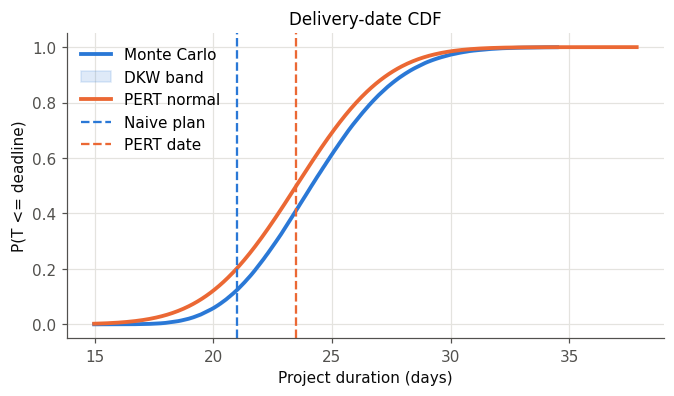

In [25]:
# Distribution of the delivery date, with a 95% band valid for all dates at once (DKW)
# 1. Plot the empirical CDF and the simultaneous DKW band.
T_sorted = np.sort(T)
keep = np.r_[0:T_sorted.size:50]
cdf = np.arange(1, T_sorted.size + 1) / T_sorted.size
radius = dkw_radius(T_sorted.size)
plt.plot(T_sorted[keep], cdf[keep], color=BLUE, linewidth=2.5, label="Monte Carlo")
plt.fill_between(T_sorted[keep], np.clip(cdf[keep] - radius, 0, 1),
                 np.clip(cdf[keep] + radius, 0, 1), color=BLUE, alpha=0.15, label="DKW band")

# 2. Compare with PERT and mark both planning dates.
x = np.linspace(T_sorted[0], T_sorted[-1], 500)
plt.plot(x, stats.norm.cdf(x, pert_mu, pert_sd), color=ORANGE, linewidth=2.5, label="PERT normal")
plt.axvline(plan, color=BLUE, linestyle="--", linewidth=1.5, label="Naive plan")
plt.axvline(pert_date, color=ORANGE, linestyle="--", linewidth=1.5, label="PERT date")
plt.xlabel("Project duration (days)")
plt.ylabel("P(T <= deadline)")
plt.title("Delivery-date CDF")
plt.legend()
plt.show()

**PERT is optimistic twice.** Its date (23.5 days) is below the expected duration (24.27 days), as
Proposition 1 predicts. Its normal law, built on one path, ignores the other paths that can overtake it:
announcing the PERT date gives a 41% chance of being on time, not 50%, and the naive plan (21 days) 12%, not 20%.
The 90% date is 28.0 days instead of 27.3. All these gaps are far larger than the error bars and than the DKW band
(±0.003 on the whole curve), so they are not sampling noise.

### 4.2 Which tasks drive the delivery date?

The **criticality index** of task $i$ is $c_i = P(i \in P^*)$, where $P^*$ is the longest path of the random
scenario (Van Slyke, 1963). It is more than a ranking: it is the sensitivity of the expected duration.

**Theorem.** Write $D_i = \mu_i + \varepsilon_i$, where $\mu_i$ is the mean of task $i$ and the noise
$\varepsilon = (\varepsilon_1, \dots, \varepsilon_k)$ has a density and finite mean. Then
$$
\frac{\partial\, \mathbb E[T]}{\partial \mu_i} = c_i = P(i \text{ is on the critical path}).
$$

*Proof.* 1. Fix $\varepsilon$. Then $T(\mu) = \max_P \sum_{j \in P} (\mu_j + \varepsilon_j)$ is a maximum of affine
functions of $\mu$. If the longest path $P^*$ is unique, it stays the longest for small changes of $\mu_i$, so
$T(\mu + h e_i) - T(\mu) = h\, \mathbf 1\{i \in P^*\}$ for $|h|$ small enough. Two different paths have equal lengths
only if a non-zero combination of the $\varepsilon_j$ takes one precise value, which has probability 0 since $\varepsilon$
has a density: $P^*$ is unique almost surely.

2. Adding $h$ to $\mu_i$ changes every path length by $h$ or by $0$, so $|T(\mu + h e_i) - T(\mu)| \le |h|$:
the difference quotients are bounded by 1.

3. A constant bound is integrable, so dominated convergence lets us exchange the limit and the expectation:
$\partial_{\mu_i} \mathbb E[T] = \lim_{h \to 0} \mathbb E\big[(T(\mu + h e_i) - T(\mu))/h\big] = \mathbb E\big[\mathbf 1\{i \in P^*\}\big] = c_i$. $\square$

**Meaning for a manager:** $c_i$ is the number of days gained on the expected delivery date per day saved on
task $i$. A task with $c_i = 1$ is always critical; saving time on a task with $c_i \approx 0$ is useless.

We estimate every $c_i$ with the critical paths of 100,000 simulations, then check the theorem directly: simulate
$T$ with and without adding $h = 0.01$ day to task $i$, **on the same random durations** (common random numbers).
The two values of $T$ are strongly correlated, so $\mathrm{Var}(T_h - T) = \mathrm{Var}\, T_h + \mathrm{Var}\, T - 2\,\mathrm{Cov}(T_h, T)$
is tiny and the finite difference $(T_h - T)/h$ is precise.

In [26]:
def criticality_index(project, model, n, rng=None):
    """Monte Carlo estimate of c_j = P(task j is on the longest path), for every task j."""
    return project.critical_tasks(model.sample(n, rng)).mean(axis=0)


def shift_sensitivity(project, model, task, h, n, rng=None):
    """Finite difference (E[T with h added to `task`] - E[T]) / h, with common random numbers:
    the SAME scenarios are used with and without the shift."""
    D = model.sample(n, rng)
    shifted = D.copy()
    shifted[:, task] += h
    return mean_ci((project.completion_time(shifted) - project.completion_time(D)) / h)

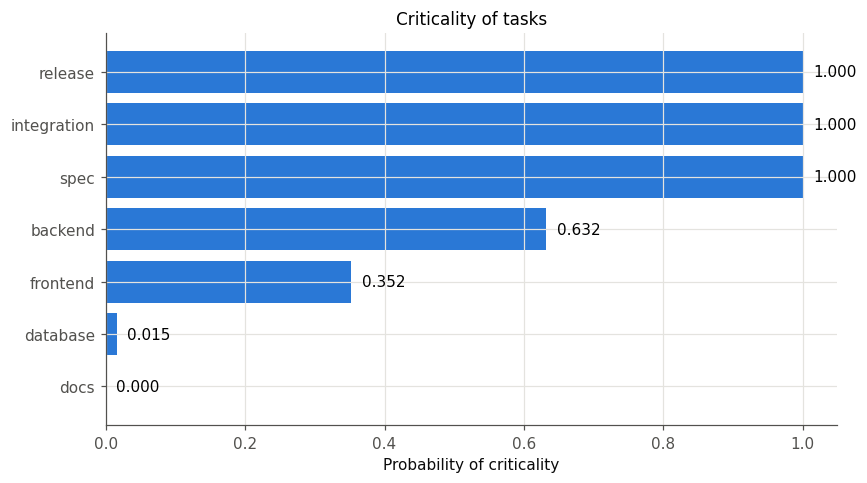

In [27]:
# Criticality index of each task
# 1. Estimate each task probability of lying on the longest path.
crit = criticality_index(project, pert_model, n=100_000, rng=SEED)
order = np.argsort(crit)

# 2. Draw one sorted horizontal bar chart.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(np.arange(project.k), crit[order], color=BLUE)
ax.set_yticks(np.arange(project.k), [project.names[i] for i in order])
ax.set_xlabel("Probability of criticality")
ax.set_xlim(0, 1.05)
ax.set_title("Criticality of tasks")
for y, i in enumerate(order):
    ax.text(crit[i] + 0.015, y, f"{crit[i]:.3f}", va="center")
plt.tight_layout()
plt.show()

In [28]:
# Check the theorem: finite differences with common random numbers
# 1. Estimate the derivative of E[T] for every task (crit comes from the chart above).
rows = []
for i, name in enumerate(project.names):
    slope = shift_sensitivity(project, pert_model, task=i, h=0.01, n=100_000, rng=SEED)
    rows.append([name, crit[i], slope.value, slope.interval])

# 2. Display criticality beside the finite-difference slope.
criticality_table = pd.DataFrame(rows, columns=["Task", "Criticality index", "Finite-difference slope", "95% interval"])
display(criticality_table.set_index("Task").style.format(precision=4,
        subset=["Criticality index", "Finite-difference slope"]))

,Criticality index,Finite-difference slope,95% interval
Task,,,
spec,1.0000,1.0000,"[1, 1]"
backend,0.6322,0.6329,"[0.6299, 0.6359]"
frontend,0.3524,0.3530,"[0.35, 0.3559]"
database,0.0154,0.0154,"[0.01467, 0.01619]"
docs,0.0000,0.0000,"[0, 0]"
integration,1.0000,1.0000,"[1, 1]"
release,1.0000,1.0000,"[1, 1]"


**PERT looks at the wrong tasks.** Its critical path is spec, backend, integration, release, and it calls
frontend non-critical (mean 10.0 days against 11.2 for backend). Monte Carlo puts frontend on the critical path
35% of the time and database 1.5% of the time. Saving one day on frontend saves 0.35 day on average; saving a day on
docs saves nothing. The finite differences agree with the criticality index to the third decimal, as the theorem predicts.

### 4.3 Real-size networks: PSPLIB J30 with SiP delays

PSPLIB (Kolisch & Sprecher, 1997) is the standard benchmark of project networks. Its J30 family has 480
networks of 30 tasks, each with a planned duration per task and its critical-path length. We keep the network and
the plan, and multiply each planned duration by a ratio actual / estimate drawn at random among the 12,299 SiP
tasks: the projects are planned like PSPLIB projects and late like a real software team. Using past overruns to
forecast a new project is called reference-class forecasting (Flyvbjerg, 2006).

These are synthetic networks with independent delays borrowed from software tasks: the numbers below describe
this model, not measured projects (Section 5.6 discusses how far they transfer).

In [29]:
# Reading PSPLIB networks (the J30 family is downloaded the first time, about 1 MB)
PSPLIB_URL = "https://www.om-db.wi.tum.de/psplib/download_dataset.php?set={}&mode=sm&format=zip"
SECTIONS = {"PROJECT INFORMATION": "info", "PRECEDENCE RELATIONS": "precedence",
            "REQUESTS/DURATIONS": "durations", "RESOURCEAVAILABILITIES": None}


def psplib_files(family="j30"):
    """Download and unzip one PSPLIB family if needed, and return its .sm files, sorted."""
    archive, folder = DATA_DIR / "psplib" / f"{family}.sm.zip", DATA_DIR / "psplib" / family
    fetch(PSPLIB_URL.format(family), archive)
    if not folder.exists():
        with zipfile.ZipFile(archive) as z:
            z.extractall(folder)
    return sorted(folder.rglob("*.sm"))


def read_psplib(path):
    """Read a PSPLIB .sm file: the durations and precedence graph (resources are ignored).

    Jobs are numbered from 1 in the file and from 0 here; the first and last jobs are dummy
    tasks of duration 0. Returns (project, info), where info["mpm_time"] is the critical-path
    length given in the file: a free check of the parser.
    """
    section, successors, durations, info = None, {}, {}, {"name": Path(path).stem}
    for line in Path(path).read_text().splitlines():
        title = next((t for t in SECTIONS if line.startswith(t)), None)
        if title:
            section = SECTIONS[title]
            continue
        values = line.split()
        if not values or not values[0].isdigit():  # column names, lines of stars
            continue
        values = [int(v) for v in values]
        if section == "info":          # pronr. #jobs rel.date duedate tardcost MPM-Time
            info["mpm_time"] = values[5]
        elif section == "precedence":  # jobnr. #modes #successors successor_1 successor_2 ...
            successors[values[0] - 1] = [j - 1 for j in values[3:3 + values[2]]]
        elif section == "durations":   # jobnr. mode duration R1 R2 R3 R4
            durations[values[0] - 1] = values[2]
    k = len(durations)
    project = Project.from_successors([durations[j] for j in range(k)], [successors[j] for j in range(k)])
    return project, info

In [30]:
# One PSPLIB network in detail
# 1. Read the first J30 network and impose SiP delays on its planned durations.
files = psplib_files("j30")
network, info = read_psplib(files[0])
net_model = EmpiricalRatio(network.durations, ratios)

# 2. Simulate 100,000 scenarios and report the decision quantities.
D = net_model.sample(100_000, rng=np.random.default_rng(SEED))
T_psp = network.completion_time(D)
plan_psp = network.planned_duration()
mean_psp = mean_ci(T_psp)
q90_psp = quantile_ci(T_psp, 0.9)
prob_psp = prob_ci(T_psp <= plan_psp)
detail = pd.DataFrame({
    "Estimate": [plan_psp, mean_psp.value, q90_psp.value, prob_psp.value],
    "95% interval": ["planned", mean_psp.interval, q90_psp.interval, prob_psp.interval],
}, index=["Planned date", "E[T]", "90% date", "P(on time)"])
display(detail)

,Estimate,95% interval
Planned date,41.000000,planned
E[T],130.778637,"[129.5, 132.1]"
90% date,167.291886,"[165.3, 169.1]"
P(on time),0.010900,"[0.006605, 0.01519]"


In [31]:
# All 480 J30 networks
# 1. Sample each network with the SiP ratio bootstrap, after checking the parser against the file.
rows = []
for path in files:
    network, info = read_psplib(path)
    net_model = EmpiricalRatio(network.durations, ratios)
    D = net_model.sample(20_000, rng=np.random.default_rng(SEED))
    T = network.completion_time(D)
    plan_net = network.planned_duration()
    assert plan_net == info["mpm_time"]  # our longest path equals the one given in the file
    criticality = network.critical_tasks(D).mean(axis=0)
    real_tasks = network.durations > 0
    near_count = int(np.sum((criticality > 0.05) & real_tasks))
    rows.append({
        "network": info["name"],
        "plan (days)": plan_net,
        "E[T]/plan": mean_ci(T).value / plan_net,
        "90% date / plan": quantile_ci(T, 0.9).value / plan_net,
        "P(on time)": prob_ci(T <= plan_net).value,
        "near-critical tasks": near_count,
    })

# 2. Store and summarize the 480-network results.
j30 = pd.DataFrame(rows)
display(j30.describe())

,plan (days),E[T]/plan,90% date / plan,P(on time),near-critical tasks
count,480.000000,480.000000,480.000000,480.000000,480.000000
mean,52.275000,2.845803,3.743401,0.021630,24.062500
std,8.877936,0.265896,0.333380,0.014052,2.410886
min,31.000000,2.076767,2.741236,0.001800,16.000000
25%,46.000000,2.656409,3.504270,0.011187,23.000000
50%,53.000000,2.814798,3.704126,0.018075,24.000000
75%,58.000000,3.025367,3.974760,0.028663,26.000000
max,98.000000,3.672072,4.814796,0.079900,30.000000


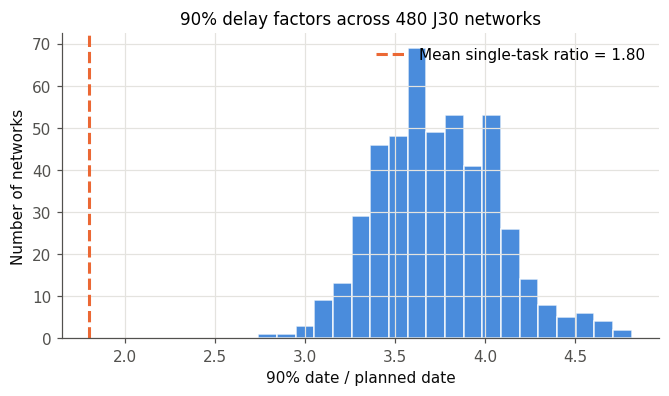

In [32]:
# How late are real-size projects?
# 1. Plot the distribution of delay factors.
plt.hist(j30["90% date / plan"], bins=20, color=BLUE, alpha=0.85, edgecolor="white")
plt.axvline(ratios.mean(), color=ORANGE, linestyle="--", linewidth=2,
            label=f"Mean single-task ratio = {ratios.mean():.2f}")
plt.xlabel("90% date / planned date")
plt.ylabel("Number of networks")
plt.title("90% delay factors across 480 J30 networks")
plt.legend()
plt.show()

**With SiP delays, a 30-task network is much later than a single task.** One task takes 1.8 times its
estimate on average. The J30 networks take 2.85 times their plan on average, their 90% date is 3.74 times the plan,
and they finish on time in about 2% of the scenarios (for j3010_1: planned 41 days, expected 131 days, on time 1.1%
of the time). The delivery date is the maximum over many competing paths, so it picks up the unlucky ones:
this is the merge effect of Proposition 1, amplified by heavy-tailed delays.

### 4.4 What makes a network fragile?

A task is **near-critical** if its criticality index exceeds 5%: it has a real chance of driving the date.
For each network we count these tasks and compare with the delay factor.

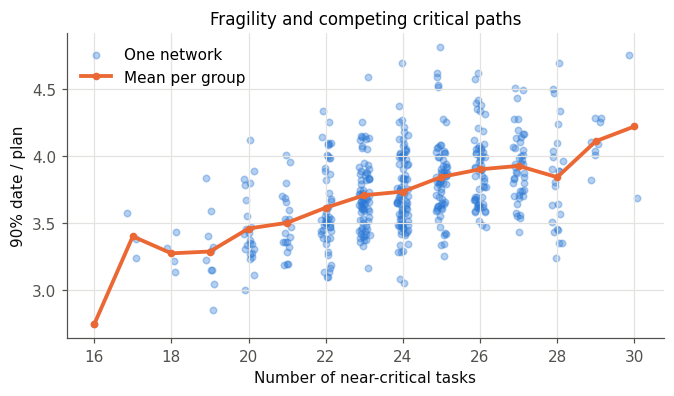

,90% date / plan,near-critical tasks,plan (days)
90% date / plan,1.000000,0.482341,-0.772922
near-critical tasks,0.482341,1.000000,-0.305612
plan (days),-0.772922,-0.305612,1.000000


In [33]:
# Delay factor versus the number of near-critical tasks
# 1. Scatter the networks and overlay the mean delay for each group.
jitter = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(j30))
plt.scatter(j30["near-critical tasks"] + jitter, j30["90% date / plan"],
            color=BLUE, alpha=0.35, s=18, label="One network")
means = j30.groupby("near-critical tasks")["90% date / plan"].mean()
plt.plot(means.index, means.values, color=ORANGE, linewidth=2.5,
         marker="o", markersize=4, label="Mean per group")
plt.xlabel("Number of near-critical tasks")
plt.ylabel("90% date / plan")
plt.title("Fragility and competing critical paths")
plt.legend()
plt.show()

# 2. Display the pairwise correlations.
correlation = j30[["90% date / plan", "near-critical tasks", "plan (days)"]].corr()
display(correlation)

**More competing paths, later projects.** The 90% delay factor grows with the number of near-critical tasks
(correlation 0.48): the more paths can become the longest, the larger the maximum, as in Proposition 1. It falls
with the length of the plan (correlation −0.77): a long critical path adds up many tasks, so independent ratios
partly average out, while a short one can be dominated by a single extreme SiP ratio. Long projects are still late
in days, just less in proportion.

### Summary of Part 4

* On the running example, the PERT date is met only 41% of the time (not 50%), and PERT misses a task that is
  critical 35% of the time.
* The criticality index is the derivative of $\mathbb E[T]$ with respect to a task's mean, and Monte Carlo gives it
  for free, with the same simulations.
* Under our model (PSPLIB networks, SiP delays), 30-task projects take 2.85 times their plan on average and are on
  time about 2% of the time; networks with many near-critical tasks are the most fragile.

---
## 5. Limitations: where Monte Carlo struggles

Parts 1 to 4 showed that Monte Carlo gives delivery dates with honest error bars when durations are well behaved.
This part looks for the cases where that promise fails. Real overruns have a heavy tail (5.1), which slows
convergence (5.2) and breaks the CLT error bar (5.3); rare delays need importance sampling (5.4); and no number of
simulations can fix a wrong model (5.5).

In [34]:
# The running example with real delays: each task takes its plan times a SiP ratio
sip_model = EmpiricalRatio(project.durations, ratios)
plan = project.planned_duration()

### 5.1 How heavy is the tail of real overruns?

A ratio $R$ has a **heavy tail of index $\alpha > 0$** if $P(R > x) \approx C x^{-\alpha}$ for large $x$. Then
$$
\mathbb E[R^p] = \int_0^\infty p\, x^{p-1} P(R > x)\, dx < \infty \iff p < \alpha ,
$$
because the integrand behaves like $x^{p - 1 - \alpha}$ at infinity. The mean is finite only if $\alpha > 1$ and the
variance only if $\alpha > 2$: **when $\alpha \le 2$, the CLT of Proposition 3 does not apply.**

To estimate $\alpha$, sort the sample as $X_{(1)} \ge X_{(2)} \ge \dots$ and keep the $k$ largest values (Hill, 1975):
$$
\frac{1}{\hat\alpha_k} = \frac1k \sum_{i=1}^{k} \ln \frac{X_{(i)}}{X_{(k+1)}} .
$$
For a Pareto law, $P(X > x) = (x_{\min}/x)^{\alpha}$, so $P\big(\ln(X/x_{\min}) > y\big) = e^{-\alpha y}$: the log-excess is
exponential with rate $\alpha$, hence of mean $1/\alpha$. Above the threshold $X_{(k+1)}$, the $k$ largest values are again
Pareto with the same $\alpha$, so the average of their log-excesses estimates $1/\alpha$. Small $k$ gives a noisy estimate,
large $k$ uses values that are no longer in the tail.

In [35]:
def hill_tail_index(x, k):
    """Hill (1975) estimate of the tail index alpha from the k largest values."""
    X = np.sort(np.asarray(x, dtype=float))[::-1]  # decreasing order
    return 1 / np.mean(np.log(X[:k] / X[k]))

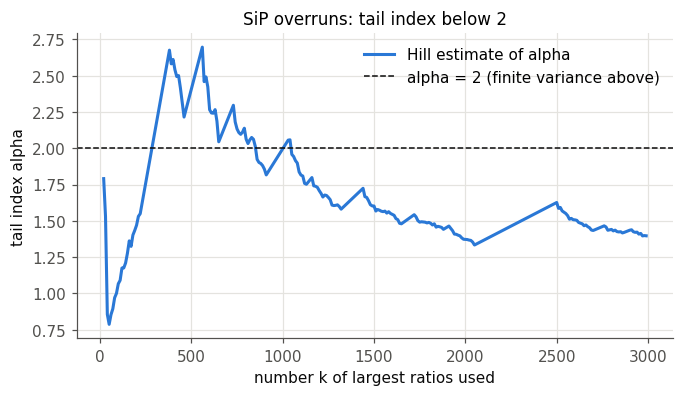

Hill estimate for k in [1000, 3000]: 1.33 to 2.06


In [36]:
# Hill plot of the SiP ratios
ks = np.arange(20, 3000, 10)
alpha_hat = np.array([hill_tail_index(ratios, k) for k in ks])

fig, ax = plt.subplots()
ax.plot(ks, alpha_hat, color=BLUE, label="Hill estimate of alpha")
ax.axhline(2, color=INK, lw=1, ls="--", label="alpha = 2 (finite variance above)")
ax.set(xlabel="number k of largest ratios used", ylabel="tail index alpha",
       title="SiP overruns: tail index below 2")
ax.legend()
plt.show()

stable = (ks >= 1000) & (ks <= 3000)
print(f"Hill estimate for k in [1000, 3000]: {alpha_hat[stable].min():.2f} to {alpha_hat[stable].max():.2f}")

**The SiP overruns have a tail index below 2.** For $k$ between 1,000 and 3,000 the Hill estimate stays between 1.33
and 1.7, apart from a short excursion up to 2.06 for $k \approx 1{,}000$ to $1{,}040$. The straight segments are blocks of
tied ratios (SiP hours are rounded): inside a block $X_{(k+1)}$ is constant and $\hat\alpha_k$ grows linearly in $k$.

**A finite sample cannot prove an infinite variance.** The empirical variance of 12,299 ratios is always finite, and a
law cut off at the largest observed ratio (281) fits the data just as well. What the Hill plot says is that, over the
observed range, the tail decays like $x^{-1.5}$: the variance is dominated by a handful of tasks and keeps growing as
more data arrive. Flyvbjerg et al. (2022) find the same power-law tail in the cost overruns of 5,392 IT projects.

### 5.2 Slow and erratic convergence

For each of three models of the running example (Beta-PERT, SiP ratios, Pareto ratios with $\alpha = 1.5$ and
$\mathbb E[R] = 1$), we run 5 independent studies of $n = 100{,}000$ simulations and plot the running estimate of $\mathbb E[T]$.

In [37]:
class ParetoRatio(DurationModel):
    """D_i = planned_i x R_i with R_i ~ Pareto: P(R > r) = (scale / r)^alpha for r >= scale.

    E[R] is finite only if alpha > 1, Var(R) only if alpha > 2. The default scale (alpha - 1) / alpha
    gives E[R] = 1: estimates right on average.
    """

    def __init__(self, planned, alpha, scale=None):
        self.planned = np.asarray(planned, dtype=float)
        self.alpha = float(alpha)
        self.scale = (self.alpha - 1) / self.alpha if scale is None else float(scale)
        self.k = len(self.planned)

    def ppf(self, U):
        return self.planned * self.scale * (1 - U) ** (-1 / self.alpha)  # inverse of 1 - (scale / r)^alpha

    def mean(self):
        a = self.alpha
        return np.full(self.k, np.inf) if a <= 1 else self.planned * self.scale * a / (a - 1)

    def var(self):
        a = self.alpha
        if a <= 2:
            return np.full(self.k, np.inf)
        return self.planned**2 * self.scale**2 * a / ((a - 1) ** 2 * (a - 2))


def running_mean(x):
    """The estimate after m simulations, (1/m) sum_{s <= m} x_s, for m = 1, ..., n."""
    x = np.asarray(x, dtype=float)
    return np.cumsum(x) / np.arange(1, len(x) + 1)

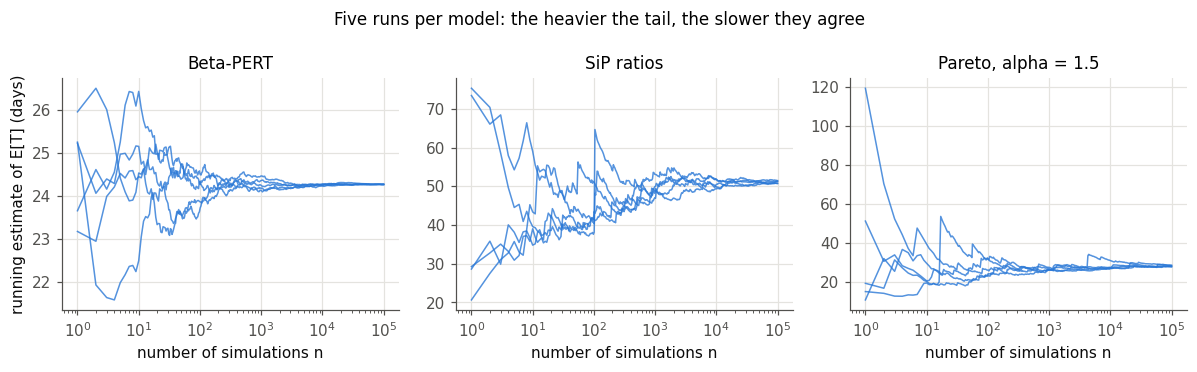

In [38]:
# Running estimate of E[T] for three delay models
n, runs = 100_000, 5
models = {
    "Beta-PERT": pert_model,
    "SiP ratios": sip_model,
    "Pareto, alpha = 1.5": ParetoRatio(project.durations, alpha=1.5),
}
rng = np.random.default_rng(SEED)
points = np.unique(np.geomspace(1, n, 400).astype(int))  # ~400 log-spaced sample sizes

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, model) in zip(axes, models.items()):
    for run in range(runs):
        T = simulate(project, model, n, rng=rng)
        ax.plot(points, running_mean(T)[points - 1], color=BLUE, lw=1, alpha=0.8)
    ax.set_xscale("log")
    ax.set(title=name, xlabel="number of simulations n")
axes[0].set_ylabel("running estimate of E[T] (days)")
fig.suptitle("Five runs per model: the heavier the tail, the slower they agree", fontsize=11)
fig.tight_layout()
plt.show()

**The heavier the tail, the longer the runs disagree.** With Beta-PERT the five runs agree within a fraction of a day
after about 1,000 simulations. With SiP and Pareto ratios they still differ by several days at $n = 1{,}000$, and each
curve jumps whenever a huge ratio is drawn.

**With $\alpha = 1.5$, ten times more precision costs a thousand times more simulations.** When $1 < \alpha < 2$, the
generalised CLT replaces $n^{-1/2}$ by $n^{1/\alpha - 1}$: the error $\hat\mu_n - \mu$ is of order $n^{-1/3}$, with a stable
(non-Gaussian) limit.

### 5.3 Error bars that lie

We repeat the coverage experiment of Section 3.8 for $n = 100$, $1{,}000$ and $10{,}000$, with 400 independent studies
each: how often does the 95% CLT interval $\hat\mu_n \pm 1.96\, \hat\sigma_n / \sqrt n$ contain the true $\mathbb E[T]$?
For Beta-PERT and SiP the truth comes from 1,000,000 simulations. For the Pareto model we use a 4-task chain, whose
$\mathbb E[T] = 5 + 10 + 5 + 1 = 21$ days is known exactly (a sum of means). The order-statistics interval for the
90% date (Proposition 5) is the control.

In [39]:
# Coverage of 95% intervals as n grows
sizes, reps = (100, 1_000, 10_000), 400

# 1. True values. Pareto chain: E[T] = sum of the means = 21 exactly. PERT and SiP: one large run.
chain = Project([5, 10, 5, 1], [[], [0], [1], [2]])
chain_model = ParetoRatio(chain.durations, alpha=1.5)
true_chain = chain_model.mean().sum()
T_pert = simulate(project, pert_model, 1_000_000, rng=SEED)
T_sip = simulate(project, sip_model, 1_000_000, rng=SEED)
true_pert, true_sip, true_sip_q90 = T_pert.mean(), T_sip.mean(), np.quantile(T_sip, 0.9)
print(f"true values: E[T] Beta-PERT = {true_pert:.3f}, E[T] SiP = {true_sip:.3f}, "
      f"90% date SiP = {true_sip_q90:.3f}, E[T] Pareto chain = {true_chain:g}")

# 2. Coverage of each interval, for each n.
cases = {
    "Beta-PERT, CLT for E[T]": (project, pert_model, mean_ci, true_pert),
    "SiP, CLT for E[T]": (project, sip_model, mean_ci, true_sip),
    "Pareto chain, CLT for E[T]": (chain, chain_model, mean_ci, true_chain),
    "SiP, order statistics for 90% date": (project, sip_model, lambda T: quantile_ci(T, 0.9), true_sip_q90),
}
table = pd.DataFrame(index=list(cases), columns=[f"n = {n:,}" for n in sizes], dtype=float)
for name, (proj, model, interval_fn, truth) in cases.items():
    for n in sizes:
        sample_fn = lambda rng, proj=proj, model=model, n=n: simulate(proj, model, n, rng=rng)
        table.loc[name, f"n = {n:,}"] = coverage(sample_fn, interval_fn, truth, reps=reps, rng=SEED)

# 3. One table, target 95%.
display(table.style.format("{:.1%}").set_caption("coverage of 95% intervals (400 repetitions)"))

true values: E[T] Beta-PERT = 24.265, E[T] SiP = 51.191, 90% date SiP = 76.381, E[T] Pareto chain = 21


,n = 100,"n = 1,000","n = 10,000"
"Beta-PERT, CLT for E[T]",94.5%,95.0%,94.8%
"SiP, CLT for E[T]",69.8%,93.0%,95.0%
"Pareto chain, CLT for E[T]",76.5%,78.2%,77.5%
"SiP, order statistics for 90% date",95.8%,96.0%,93.5%


**The CLT interval keeps its promise only when the tail is light.** Beta-PERT covers 94.5% to 95.0% for every $n$.
With SiP ratios the coverage is 69.8% at $n = 100$ and reaches 95.0% only at $n = 10{,}000$. With Pareto ratios it
stays between 76.5% and 78.2% whatever $n$: more simulations do not help.

The interval plugs $\hat\sigma_n$ in place of $\sigma$. With a heavy tail, $\hat\sigma_n$ is driven by a few extreme values:
in most studies the huge delays have not been drawn yet, so $\hat\mu_n$ and $\hat\sigma_n$ are both too small and the
interval is too short and too low. When $\alpha < 2$, $\sigma = \infty$ and this never improves. The SiP bootstrap has a
finite variance only because its ratios are capped at 281, so its CLT kicks in, but late.

**The distribution-free interval keeps its promise.** The order-statistics interval for the 90% date covers 93.5% to
96.0% of the time, within the $\pm 2.2$ points of noise of 400 repetitions, as Proposition 5 guarantees without any
moment assumption. With heavy tails we should report quantiles with order-statistics intervals and probabilities
with Hoeffding intervals, and distrust a CLT error bar on $\mathbb E[T]$.

### 5.4 Rare events: importance sampling

For a small probability $p = P(T > t)$, the plain estimator $\hat p_n$ has standard deviation $\sqrt{p(1-p)/n}$, so its
**relative error** is
$$
\frac{\sqrt{p(1-p)/n}}{p} = \sqrt{\frac{1-p}{np}} \approx \frac{1}{\sqrt{np}} .
$$
It depends on the expected number $np$ of rare events observed. For $p \approx 10^{-3}$ and $n = 10^5$ we see about 100
of them, hence about 10% (20% at 95%); 1% at 95% would need $n \approx 4 \times 10^{7}$.

**Importance sampling** draws the scenario from a proposal $g$ that makes delays more frequent and corrects with the
weight $w = f/g$, where $f$ is the true law. Here a scenario is the vector $J = (J_1, \dots, J_k)$ of the SiP ratios given
to the $k$ tasks, with $f(J) = m^{-k}$. If $g(J) > 0$ for every $J$,
$$
\mathbb E_g\Big[\mathbf 1\{T(J) > t\}\, \frac{f(J)}{g(J)}\Big] = \sum_J g(J)\, \mathbf 1\{T(J) > t\}\, \frac{f(J)}{g(J)}
= \sum_J f(J)\, \mathbf 1\{T(J) > t\} = p ,
$$
so the estimator $\frac1n \sum_s \mathbf 1\{T^{(s)} > t\}\, w^{(s)}$ is **unbiased for every proposal**. Its variance, however,
depends strongly on $g$.

We tilt each ratio towards long tasks: $r_j$ is drawn with probability $q_j = r_j^\theta / \sum_l r_l^\theta$ instead of $1/m$
($\theta = 0$ is plain Monte Carlo).
* **Tilt all tasks:** every $J_i \sim q$, so $g(J) = \prod_i q_{J_i}$ and $w = \prod_{i=1}^{k} \dfrac{1}{m\, q_{J_i}}$.
* **Tilt one task:** a task $I$ chosen uniformly is drawn from $q$, the others uniformly. Averaging over $I$,
  $g(J) = \frac1k \sum_i q_{J_i}\, m^{-(k-1)}$, so $w = \Big(\frac1k \sum_{i=1}^{k} m\, q_{J_i}\Big)^{-1}$.

The second proposal follows the **one big jump** principle: for i.i.d. heavy-tailed (subexponential) $R_i$,
$P(R_1 + \dots + R_k > x) \sim P(\max_i R_i > x) \sim k\, P(R_1 > x)$ as $x \to \infty$. A huge total delay is typically caused
by one huge task, not by every task being a bit late.

In [40]:
def tail_probability_is(project, planned, ratios, t, theta, n, rng=None, tilt="one"):
    """Importance-sampling estimate of p = P(T > t) when D_i = planned_i x R_i, R_i drawn among `ratios`.

    The ratio j is drawn with probability q_j proportional to r_j^theta (theta = 0: plain Monte Carlo),
    for every task (tilt="all") or for one task chosen at random (tilt="one"), and each scenario is
    reweighted by w = f / g. Weights are computed in logs to avoid overflow.
    """
    rng = np.random.default_rng(rng)
    planned = np.asarray(planned, dtype=float)
    ratios = np.asarray(ratios, dtype=float)
    m, k = len(ratios), project.k

    # 1. Tilted law q_j proportional to r_j^theta, in logs (log-sum-exp).
    a = theta * np.log(ratios)
    log_q = a - (a.max() + np.log(np.exp(a - a.max()).sum()))
    q = np.exp(log_q)
    q /= q.sum()  # rng.choice wants probabilities that sum to 1 exactly

    # 2. Draw the ratio indices J (n, k) and the log-weights log(f / g).
    if tilt == "all":    # w = prod_i 1 / (m q_{J_i})
        J = rng.choice(m, size=(n, k), p=q)
        log_w = -(np.log(m) + log_q[J]).sum(axis=1)
    elif tilt == "one":  # w = 1 / ((1/k) sum_i m q_{J_i})
        J = rng.integers(m, size=(n, k))
        I = rng.integers(k, size=n)
        J[np.arange(n), I] = rng.choice(m, size=n, p=q)
        b = np.log(m) + log_q[J]  # log(m q_{J_i})
        b_max = b.max(axis=1, keepdims=True)
        log_w = -(b_max[:, 0] + np.log(np.exp(b - b_max).mean(axis=1)))
    else:
        raise ValueError("tilt must be 'all' or 'one'")

    # 3. Weighted indicators 1{T > t} w.
    T = project.completion_time(planned * ratios[J])
    return mean_ci((T > t) * np.exp(log_w))

In [41]:
# P(T > 80 x plan): plain Monte Carlo versus importance sampling, same budget
t = 80 * plan
n = 100_000

# 1. Reference: 4,000,000 plain simulations, in 4 batches of 1,000,000 to limit memory.
rng = np.random.default_rng(SEED)
late = np.concatenate([simulate(project, sip_model, 1_000_000, rng=rng) > t for _ in range(4)])
reference = prob_ci(late, method="clt")
print(f"reference P(T > {t:g} days) = {reference.value:.3e}  "
      f"(relative error 95%: {reference.radius / reference.value:.1%}, n = {reference.n:,})")

# 2. Same budget n = 100,000 for each tilt and each theta (theta = 0 is plain Monte Carlo).
rows = {}
for tilt in ["all", "one"]:
    for theta in [0, 0.5, 1, 1.5, 2, 3]:
        est = tail_probability_is(project, project.durations, ratios, t, theta, n=n,
                                     rng=SEED, tilt=tilt)
        rows[(tilt, theta)] = {"estimate": est.value, "relative error (95%)": est.radius / est.value,
                               "radius": est.radius}
results = pd.DataFrame(rows).T.rename_axis(["tilt", "theta"])
display(results[["estimate", "relative error (95%)"]].unstack("tilt").style
        .format("{:.3e}", subset=["estimate"]).format("{:.1%}", subset=["relative error (95%)"])
        .format_index("{:g}", axis=0))

# 3. Variance reduction of tilt "one" against plain Monte Carlo, same n: (radius ratio)^2.
plain_radius = results.loc[("one", 0), "radius"]
for theta in [1, 2, 3]:
    print(f"tilt 'one', theta = {theta}: variance divided by "
          f"{(plain_radius / results.loc[('one', theta), 'radius']) ** 2:.0f}")

reference P(T > 1680 days) = 8.718e-04  (relative error 95%: 3.3%, n = 4,000,000)


tilt 'one', theta = 1: variance divided by 20
tilt 'one', theta = 2: variance divided by 275
tilt 'one', theta = 3: variance divided by 483


**Tilting one task works; tilting all tasks fails.** The reference from 4,000,000 plain simulations is
$p \approx 8.7 \times 10^{-4}$ (relative error 3.3%). With the same budget $n = 100{,}000$, plain Monte Carlo has a
relative error of 21%, while "tilt one" gives $9.1 \times 10^{-4}$ with 1.2% at $\theta = 2$ and 0.9% at $\theta = 3$. The
variance is divided by about 275 at $\theta = 2$ (483 at $\theta = 3$): 100,000 tilted simulations are worth tens of
millions of plain ones. The tilted estimates sit about two reference standard errors above $8.7 \times 10^{-4}$, and they
are the more precise of the two.

**"Tilt all" gives estimates that are wrong by orders of magnitude for $\theta \ge 1.5$.** At $\theta = 2$ and $3$ it
returns $1.8 \times 10^{-7}$ and $5.1 \times 10^{-10}$, and the CLT interval at $\theta = 2$ excludes the true value. Its weight is a
product of $k = 7$ factors: making every task long creates scenarios the true law almost never produces, so most
weights are tiny and the mean is driven by rare huge weights that a finite sample misses.

**The one-big-jump principle explains the difference.** Under the true law, $T > 80 \times$ plan happens because one
task takes a huge ratio, which is exactly what "tilt one" simulates. Its weight satisfies $w \le k / (m\, q_{J_I})$, which
is small whenever the tilted task is long, so the weights stay bounded on the rare event.

### 5.5 Model risk: Monte Carlo cannot fix a wrong model

So far the tasks were independent. We compare with the opposite extreme, one common ratio $R$ for all tasks (same
team, same estimator, same optimism), keeping the same SiP law for each task.

In [42]:
# Independent tasks versus one common ratio for all tasks
n, k = 100_000, project.k
rng = np.random.default_rng(SEED)

# 1. Same marginal law for each task; only the dependence between tasks changes.
U_independent = rng.random((n, k))
U_common = np.repeat(rng.random((n, 1)), k, axis=1)  # one ratio quantile for all tasks

# 2. E[T], 90% date and P(on time at plan), each with its 95% interval.
rows = {}
for name, U in [("independent tasks", U_independent), ("one common ratio", U_common)]:
    T = project.completion_time(sip_model.ppf(U))
    mean, q90, on_time = mean_ci(T), quantile_ci(T, 0.9), prob_ci(T <= plan)
    rows[name] = {"E[T] (days)": mean.value, "E[T] 95% CI": mean.interval,
                  "90% date (days)": q90.value, "90% date 95% CI": q90.interval,
                  "P(on time at plan)": on_time.value, "P(on time) 95% CI": on_time.interval}
display(pd.DataFrame(rows).T.style.format("{:.2f}", subset=["E[T] (days)", "90% date (days)"])
        .format("{:.3f}", subset=["P(on time at plan)"]))

,E[T] (days),E[T] 95% CI,90% date (days),90% date 95% CI,P(on time at plan),P(on time) 95% CI
independent tasks,51.39,"[50.72, 52.06]",76.32,"[75.86, 76.75]",0.160,"[0.1562, 0.1648]"
one common ratio,38.13,"[37.23, 39.04]",68.25,"[66, 69.13]",0.620,"[0.6154, 0.624]"


**The dependence assumption moves $P(\text{on time})$ from 16% to 62%.** With independent tasks, $P(T \le 21) = 0.160$,
$\mathbb E[T] = 51.4$ days and the 90% date is 76.3 days. With one common ratio, $P(T \le 21) = 0.620$, $\mathbb E[T] = 38.1$
days and the 90% date is 68.3 days. With a common ratio $T = 21\, R$ exactly, so $P(T \le 21) = P(R \le 1)$: the parallel
paths no longer compete (Proposition 1), and independence turns out to be the pessimistic assumption here.

**Both estimates are precise, and they disagree.** Each Hoeffding interval for $P(\text{on time})$ has a radius of about
0.004, a hundred times smaller than the gap of 0.46. A Monte Carlo error bar measures the sampling error given the
model, never the error of the model itself.

### 5.6 Other limitations

* **Transferability.** The SiP ratios come from one company's software tasks; using them on PSPLIB networks (Part 4)
  assumes these overruns transfer to other projects. DSLIB (231 real projects with baseline and tracking data) would
  allow a check on real networks with real delays.
* **Rounded reporting.** 29% of SiP tasks are exactly on estimate ($R = 1$), which reflects rounded or adjusted
  timesheets more than perfect estimates. Rounded hours also create the tied ratios visible in the Hill plot.
* **Resources ignored.** The longest-path model assumes unlimited resources. Tasks that share people or machines
  cannot run in parallel as planned, so the true dates are later.

---
## Conclusion

**Monte Carlo can be trusted for probabilities and quantiles, even with heavy tails.** For $P(\text{on time})$,
Hoeffding's interval is valid for every $n$ and every law of the durations, because the indicators lie in $[0, 1]$. The
order-statistics interval for the 90% date covered 93.5% to 96.0% of the time with SiP ratios. For $\mathbb E[T]$, the CLT
interval is reliable only with light tails, as with Beta-PERT (about 95% coverage), and Hoeffding does not apply
since $T$ is unbounded.

**It breaks down for means under heavy tails, for rare events and under model error.** Real overruns have a tail index
$\hat\alpha \approx 1.4$ to $1.7 < 2$: the running mean converges like $n^{-1/3}$ instead of $n^{-1/2}$, and the 95% CLT
interval for $\mathbb E[T]$ covers only 70% (SiP, $n = 100$) to 77% (Pareto, any $n$) of the time. For a rare delay
($p \approx 9 \times 10^{-4}$), 100,000 plain simulations leave a 21% relative error; tilting one task brings it to 1.2%
(variance divided by about 275), while tilting all tasks fails. No error bar captures model risk: independent or fully
shared delays move $P(\text{on time})$ from 16% to 62%.

**A project manager should announce a date with a probability, not a mean.** For the running example planned at 21
days, the plan is met with probability 16% under independent SiP delays, and the 90% date is about 76 days (68 days if
delays are fully shared). Announce such a quantile with its interval, state the dependence assumption behind it, and
give the range across plausible assumptions rather than one number with a misleadingly tight error bar.

---
## References

**Monte Carlo methods**
* Course notes, *Mathematics of Modern ML*, Chapter 1: Hoeffding's inequality, confidence radii, coverage experiments.
* Owen, A. B. (2013). *Monte Carlo Theory, Methods and Examples*. Chapters 2 (error estimates), 8 (antithetic variables, control variates) and 9 (importance sampling).
* Esary, J. D., Proschan, F. & Walkup, D. W. (1967). Association of random variables, with applications. *Ann. Math. Statist.* 38(5), 1466-1474.
* Massart, P. (1990). The tight constant in the Dvoretzky-Kiefer-Wolfowitz inequality. *Ann. Probab.* 18(3), 1269-1283.
* Hill, B. M. (1975). A simple general approach to inference about the tail of a distribution. *Ann. Statist.* 3(5), 1163-1174.
* Foss, S., Korshunov, D. & Zachary, S. (2013). *An Introduction to Heavy-Tailed and Subexponential Distributions*, 2nd ed. Springer (the one-big-jump principle).

**Project networks under uncertainty**
* Malcolm, D. G., Roseboom, J. H., Clark, C. E. & Fazar, W. (1959). Application of a technique for research and development program evaluation. *Oper. Res.* 7(5), 646-669.
* Clark, C. E. (1961). The greatest of a finite set of random variables. *Oper. Res.* 9(2), 145-162.
* Van Slyke, R. M. (1963). Monte Carlo methods and the PERT problem. *Oper. Res.* 11(5), 839-860.
* Sullivan, R. S., Hayya, J. C. & Schaul, R. (1982). Efficiency of the antithetic variate method for simulating stochastic networks. *Management Sci.* 28(5), 563-572.
* Sculli, D. (1983). The completion time of PERT networks. *J. Oper. Res. Soc.* 34(2), 155-158.
* Hagstrom, J. N. (1988). Computational complexity of PERT problems. *Networks* 18(2), 139-147.
* Baccelli, F., Cohen, G., Olsder, G. J. & Quadrat, J.-P. (1992). *Synchronization and Linearity: An Algebra for Discrete Event Systems*. Wiley (max-plus algebra).
* Flyvbjerg, B. (2006). From Nobel Prize to project management: getting risks right. *Project Management J.* 37(3), 5-15.
* Flyvbjerg, B., Budzier, A., Lee, J. S., Keil, M., Lunn, D. & Bester, D. W. (2022). The empirical reality of IT project cost overruns: discovering a power-law distribution. *J. Management Inf. Syst.* 39(3), 607-639.

**Data**
* SiP: Jones, D. M. & Cullum, S. (2019). A conversation around the analysis of the SiP effort estimation dataset. arXiv:1901.01621. Data: github.com/Derek-Jones/SiP_dataset (CC BY-NC-ND 4.0).
* PSPLIB: Kolisch, R. & Sprecher, A. (1997). PSPLIB, a project scheduling problem library. *European J. Oper. Res.* 96(1), 205-216.
* DSLIB: Batselier, J. & Vanhoucke, M. (2015). Construction and evaluation framework for a real-life project database. *Int. J. Project Management* 33(3), 697-710.